# Recommendation detection: fastText

Run `prepare_data.ipynb` first. Read its shared train/test rows and stored validation folds, apply the original light normalization, then search fastText configurations on train only. The test report is exploratory because the test set was examined during development. Save the selected fastText model in `output models`.


In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import string
import hazm
import matplotlib.pyplot as plt

LABELS = {"not_recommended": 0, "recommended": 1}
LABEL_NAMES = {value: key for key, value in LABELS.items()}
PROJECT_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "digikala-comments.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or one of its subdirectories.")
train_path = PROJECT_ROOT / "data" / "train.parquet"
test_path = PROJECT_ROOT / "data" / "test.parquet"
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError("Run prepare_data.ipynb to create data/train.parquet and data/test.parquet.")

train_data = pd.read_parquet(train_path, engine="pyarrow").reset_index(drop=True)
test_data = pd.read_parquet(test_path, engine="pyarrow").reset_index(drop=True)
required = {"source_row", "body", "processed_body", "recommendation_status"}
if not required.union({"fold"}).issubset(train_data.columns) or not required.issubset(test_data.columns):
    raise ValueError("Prepared data columns are missing. Run prepare_data.ipynb again.")
for frame in (train_data, test_data):
    assert frame["source_row"].is_unique
    assert not frame[list(required)].isna().any().any()
    assert set(frame["recommendation_status"]) == set(LABELS.values())
assert set(train_data["source_row"]).isdisjoint(test_data["source_row"])
assert set(train_data["processed_body"]).isdisjoint(test_data["processed_body"])

y_train = train_data["recommendation_status"]
y_test = test_data["recommendation_status"]
fold_ids = train_data["fold"]
assert fold_ids.notna().all() and fold_ids.ge(0).all()
cv = [
    (np.flatnonzero(fold_ids.to_numpy() != fold),
     np.flatnonzero(fold_ids.to_numpy() == fold))
    for fold in sorted(fold_ids.unique())
]
assert len(cv) >= 2
for train_positions, valid_positions in cv:
    assert set(y_train.iloc[train_positions]) == set(LABELS.values())
    assert set(y_train.iloc[valid_positions]) == set(LABELS.values())
print("Train:", len(train_data), "| Test:", len(test_data), "| Shared CV folds:", len(cv))


Train: 7995 | Test: 1999 | Shared CV folds: 5


## Light normalization

Apply the same text preparation as the original fastText experiment to the saved raw comment bodies. The stored row order and labels do not change.


In [8]:
normalizer = hazm.Normalizer()


def remove_chars(text, chars):
    for char in chars:
        text = text.replace(char, " ")
    return text


def preprocess_light(text):
    if not isinstance(text, str):
        return None
    text = remove_chars(text.lower(), string.punctuation + "؟،")
    text = normalizer.normalize(text).replace("آ", "ا")
    text = remove_chars(text, "۰۱۲۳۴۵۶۷۸۹")
    return " ".join(text.split()) or None


X_train_light = train_data["body"].apply(preprocess_light)
X_test_light = test_data["body"].apply(preprocess_light)
if X_train_light.isna().any() or X_test_light.isna().any():
    raise ValueError("An empty comment appeared after light normalization.")
assert X_train_light.index.equals(y_train.index)
assert X_test_light.index.equals(y_test.index)


## 5. fastText

This section needs `fasttext-wheel==0.9.2` on Windows with Python 3.12; import it as `fasttext`. Search word n-grams, optional character n-grams, learning rate, and epochs on the same five training folds. Train the selected configuration on all training rows and report its test result. fastText training writes temporary files that are removed automatically.


In [9]:
import fasttext
import tempfile
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid

FASTTEXT_DIM = 50
FASTTEXT_BUCKET = 100_000
FASTTEXT_THREADS = 2
FASTTEXT_FIXED = {
    "dim": FASTTEXT_DIM,
    "bucket": FASTTEXT_BUCKET,
    "thread": FASTTEXT_THREADS,
    "loss": "softmax",
    "verbose": 0,
}
FASTTEXT_PARAM_GRID = [
    {"wordNgrams": [1, 2], "minn": [0], "maxn": [0],
     "epoch": [10, 25], "lr": [0.1, 0.5]},
    {"wordNgrams": [1, 2], "minn": [3], "maxn": [5],
     "epoch": [10, 25], "lr": [0.1, 0.5]},
]
FASTTEXT_PARAM_KEYS = ("wordNgrams", "minn", "maxn", "epoch", "lr")


def fasttext_line(text):
    # fastText expects one sample per line; collapse embedded whitespace.
    return " ".join(str(text).split())


# Use the shared light-normalized comments in stored row order.
X_train_fasttext = X_train_light
X_test_fasttext = X_test_light


def write_fasttext_data(path, texts, labels):
    with Path(path).open("w", encoding="utf-8", newline="\n") as output:
        for text, label in zip(texts, labels, strict=True):
            output.write(f"__label__{LABEL_NAMES[int(label)]} {fasttext_line(text)}\n")


def predict_fasttext(model, texts):
    lines = [fasttext_line(text) for text in texts]
    predicted_labels, _ = model.predict(lines, k=1)
    return [LABELS[item[0].removeprefix("__label__")]
            for item in predicted_labels]


def fasttext_cv_search(texts, labels):
    """Search configurations using only training rows and the existing CV folds."""
    records = []
    folds = cv
    configurations = list(ParameterGrid(FASTTEXT_PARAM_GRID))
    with tempfile.TemporaryDirectory(prefix="vazheh_fasttext_cv_") as folder:
        training_file = Path(folder) / "train.txt"
        for number, params in enumerate(configurations, start=1):
            fold_f1, fold_accuracy = [], []
            for train_pos, valid_pos in folds:
                write_fasttext_data(
                    training_file, texts.iloc[train_pos], labels.iloc[train_pos]
                )
                model = fasttext.train_supervised(
                    input=str(training_file), **FASTTEXT_FIXED, **params
                )
                predicted = predict_fasttext(model, texts.iloc[valid_pos])
                actual = labels.iloc[valid_pos]
                fold_f1.append(f1_score(actual, predicted, average="macro"))
                fold_accuracy.append(accuracy_score(actual, predicted))
                del model
            records.append({
                **params,
                "mean_cv_macro_f1": sum(fold_f1) / len(fold_f1),
                "std_cv_macro_f1": pd.Series(fold_f1).std(ddof=0),
                "mean_cv_accuracy": sum(fold_accuracy) / len(fold_accuracy),
            })
            print(f"fastText configuration {number}/{len(configurations)} complete")
    return (pd.DataFrame(records)
            .sort_values(["mean_cv_macro_f1", "std_cv_macro_f1"],
                         ascending=[False, True])
            .reset_index(drop=True))


def fit_fasttext_on_all_train(texts, labels, params):
    with tempfile.TemporaryDirectory(prefix="vazheh_fasttext_final_") as folder:
        training_file = Path(folder) / "train.txt"
        write_fasttext_data(training_file, texts, labels)
        return fasttext.train_supervised(
            input=str(training_file), **FASTTEXT_FIXED, **params
        )

In [10]:
# Search 16 configurations × 5 training folds = 80 fastText fits.
fasttext_cv_results = fasttext_cv_search(X_train_fasttext, y_train)
display(fasttext_cv_results)
best_fasttext_params = {
    key: (int(fasttext_cv_results.loc[0, key]) if key != "lr"
          else float(fasttext_cv_results.loc[0, key]))
    for key in FASTTEXT_PARAM_KEYS
}
print("Selected fastText parameters:", best_fasttext_params)
print("Best fastText training CV macro-F1:", fasttext_cv_results.loc[0, "mean_cv_macro_f1"])

fastText configuration 1/16 complete
fastText configuration 2/16 complete
fastText configuration 3/16 complete
fastText configuration 4/16 complete
fastText configuration 5/16 complete
fastText configuration 6/16 complete
fastText configuration 7/16 complete
fastText configuration 8/16 complete
fastText configuration 9/16 complete
fastText configuration 10/16 complete
fastText configuration 11/16 complete
fastText configuration 12/16 complete
fastText configuration 13/16 complete
fastText configuration 14/16 complete
fastText configuration 15/16 complete
fastText configuration 16/16 complete


,epoch,lr,maxn,minn,wordNgrams,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_accuracy
0,10,0.1,5,3,2,0.882014,0.006629,0.882051
1,25,0.1,0,0,2,0.880661,0.006412,0.880675
2,10,0.1,5,3,1,0.879391,0.006853,0.879425
3,10,0.1,0,0,2,0.878412,0.005687,0.878424
4,25,0.1,5,3,2,0.878157,0.006866,0.878174
5,10,0.5,0,0,2,0.877034,0.005377,0.877048
6,25,0.5,0,0,2,0.874157,0.004497,0.874171
7,10,0.5,5,3,2,0.874156,0.006548,0.874171
8,25,0.5,5,3,2,0.872028,0.006247,0.872045
9,25,0.1,5,3,1,0.871404,0.007623,0.871420


Selected fastText parameters: {'wordNgrams': 2, 'minn': 3, 'maxn': 5, 'epoch': 10, 'lr': 0.1}
Best fastText training CV macro-F1: 0.8820142173663934


fastText test classification report:
                 precision    recall  f1-score   support

not_recommended      0.892     0.910     0.901      1000
    recommended      0.908     0.890     0.899       999

       accuracy                          0.900      1999
      macro avg      0.900     0.900     0.900      1999
   weighted avg      0.900     0.900     0.900      1999



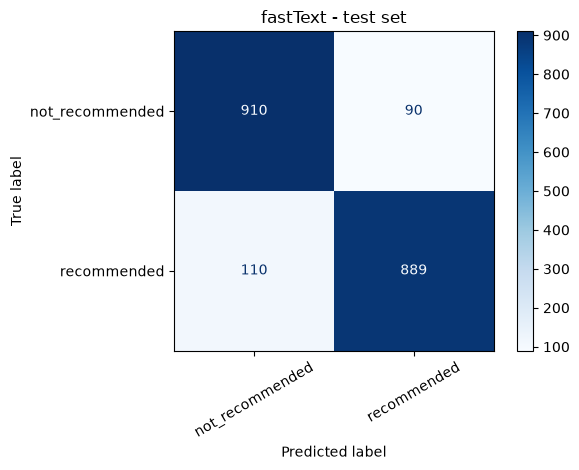

In [11]:
# Fit the selected fastText configuration on all training rows.
fasttext_model = fit_fasttext_on_all_train(X_train_fasttext, y_train, best_fasttext_params)
fasttext_test_pred = predict_fasttext(fasttext_model, X_test_fasttext)

print("fastText test classification report:")
print(classification_report(
    y_test, fasttext_test_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, fasttext_test_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("fastText - test set")
plt.tight_layout()
plt.show()


### Save the selected fastText model

Store the model trained on all train rows in fastText's native `.bin` format. It expects text prepared by `preprocess_light`. The final comparison notebook will choose the overall winner and handle delivery to Django.


In [ ]:
import json
output_dir = PROJECT_ROOT / "notebooks" / "recommendation detection" / "output models"
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "fasttext.bin"
fasttext_model.save_model(str(model_path))
print(f"Saved fastText winner to {model_path}")

# Keep the training CV score and dataset identity with this artifact.
from hashlib import sha256
metrics = {
    "approach": "fastText",
    "selected_model": "fastText supervised",
    "cv_macro_f1": float(fasttext_cv_results.loc[0, "mean_cv_macro_f1"]),
    "train_sha256": sha256(train_path.read_bytes()).hexdigest(),
    "test_sha256": sha256(test_path.read_bytes()).hexdigest(),
}
(output_dir / "fasttext_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
